# TelcoPeople — Analyse comportementale et analyse des erreurs

Ce notebook poursuit une logique simple : **comprendre les mécanismes associés aux départs avant d’ajouter de nouvelles variables au modèle**.

Quatre hypothèses sont étudiées :

1. **désengagement progressif** ;
2. **frustration salariale** ;
3. **stagnation professionnelle** ;
4. **rupture comportementale et profil atypique**.

Le notebook entraîne ensuite une baseline et analyse ses faux positifs et faux négatifs. Les nouvelles variables ne sont conservées que si elles améliorent la validation temporelle de juin 2024.

## 1. Importation des bibliothèques

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from catboost import CatBoostClassifier
from sklearn.metrics import (
    f1_score, precision_score, recall_score,
    roc_auc_score, classification_report,
    confusion_matrix
)

pd.set_option("display.max_columns", 150)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

## 2. Chargement des données

Le notebook doit être placé dans `notebooks`. Les fichiers bruts sont lus depuis `data/raw`.

In [2]:
CHEMIN = "../data/raw/"

train = pd.read_csv(CHEMIN + "telcopeople_train.csv")
test = pd.read_csv(CHEMIN + "telcopeople_test.csv")

print("Train :", train.shape)
print("Test :", test.shape)
print("Taux de départ :", round(train["target"].mean() * 100, 2), "%")

Train : (5444, 42)
Test : (1507, 41)
Taux de départ : 10.14 %


## 3. Fonction de préparation

Cette fonction harmonise les données et construit les variables techniques déjà validées lors des analyses précédentes.

In [3]:
def preparer_donnees(df):
    df = df.copy()

    df["ville_affectation"] = df["ville_affectation"].fillna("INCONNU").str.strip().str.title()
    df["departement"] = (
        df["departement"].fillna("INCONNU").str.strip().str.upper()
        .str.replace("DEPT", "DEP", regex=False)
    )
    df["contrat"] = (
        df["contrat"].fillna("INCONNU").str.strip().str.upper()
        .str.replace(".", "", regex=False)
    )
    df["niveau_etude"] = (
        df["niveau_etude"].fillna("INCONNU").str.strip().str.upper()
        .str.replace(" ", "", regex=False)
        .str.replace("BAC2", "BAC+2", regex=False)
    )

    for col in ["genre", "poste", "grade", "code_site", "source_sirh"]:
        df[col] = df[col].fillna("INCONNU").astype(str).str.strip().str.upper()

    dates = [
        "date_reference", "date_naissance", "date_embauche",
        "date_derniere_promotion", "date_derniere_absence"
    ]
    for col in dates:
        df[col] = pd.to_datetime(df[col], format="mixed", dayfirst=True, errors="coerce")

    df["salaire_mensuel"] = pd.to_numeric(
        df["salaire_mensuel"].astype(str)
        .str.replace("FCFA", "", regex=False)
        .str.replace(" ", "", regex=False),
        errors="coerce"
    )

    df["age"] = (df["date_reference"] - df["date_naissance"]).dt.days / 365.25
    df["anciennete"] = (df["date_reference"] - df["date_embauche"]).dt.days / 365.25
    df["annees_depuis_promotion"] = (
        df["date_reference"] - df["date_derniere_promotion"]
    ).dt.days / 365.25
    df["jours_depuis_absence"] = (
        df["date_reference"] - df["date_derniere_absence"]
    ).dt.days

    df["ratio_salaire_reference"] = df["salaire_mensuel"] / df["reference_salaire_grade"]
    df["ecart_salaire_reference"] = df["salaire_mensuel"] - df["reference_salaire_grade"]
    df["evolution_salaire"] = df["salaire_mensuel"] - df["salaire_12m_avant"]
    df["taux_evolution_salaire"] = (
        df["evolution_salaire"] / df["salaire_12m_avant"].replace(0, np.nan)
    )

    df["engagement_moyen"] = df[["engagement_actuel", "engagement_precedent"]].mean(axis=1)
    df["evolution_engagement"] = df["engagement_actuel"] - df["engagement_precedent"]
    df["performance_moyenne"] = df[["performance_actuelle", "performance_precedente"]].mean(axis=1)
    df["evolution_performance"] = df["performance_actuelle"] - df["performance_precedente"]

    df["jours_abs_6m"] = df[[f"jours_abs_m{i}" for i in range(1, 7)]].sum(axis=1)
    df["nb_abs_6m"] = df[[f"nb_abs_m{i}" for i in range(1, 7)]].sum(axis=1)
    df["abs_non_just_6m"] = df[[f"abs_non_just_m{i}" for i in range(1, 7)]].sum(axis=1)
    df["jours_abs_recents"] = df[["jours_abs_m1", "jours_abs_m2", "jours_abs_m3"]].sum(axis=1)
    df["jours_abs_anciens"] = df[["jours_abs_m4", "jours_abs_m5", "jours_abs_m6"]].sum(axis=1)
    df["tendance_absence"] = df["jours_abs_recents"] - df["jours_abs_anciens"]

    df["jamais_promu"] = df["date_derniere_promotion"].isna().astype(int)
    df["absence_non_renseignee"] = df["date_derniere_absence"].isna().astype(int)
    df["engagement_manquant"] = df["engagement_actuel"].isna().astype(int)
    df["performance_manquante"] = df["performance_actuelle"].isna().astype(int)

    return df.replace([np.inf, -np.inf], np.nan)

## 4. Application de la préparation

In [4]:
train_prepare = preparer_donnees(train)
test_prepare = preparer_donnees(test)

print("Train préparé :", train_prepare.shape)
print("Test préparé :", test_prepare.shape)

Train préparé : (5444, 64)
Test préparé : (1507, 63)


# Partie A — Reconstruction des mécanismes comportementaux

## 5. Hypothèse 1 : désengagement progressif

Un départ peut être précédé par un engagement faible, une baisse récente de l’engagement ou une hausse de l’absentéisme.

In [5]:
train_prepare["engagement_faible"] = (train_prepare["engagement_actuel"] < 3).astype(int)
train_prepare["engagement_en_baisse"] = (train_prepare["evolution_engagement"] < -0.30).astype(int)
train_prepare["absence_en_hausse"] = (train_prepare["tendance_absence"] > 1).astype(int)

train_prepare["mecanisme_desengagement"] = (
    train_prepare["engagement_faible"] +
    train_prepare["engagement_en_baisse"] +
    train_prepare["absence_en_hausse"]
)

analyse_desengagement = train_prepare.groupby("mecanisme_desengagement")["target"].agg(
    effectif="count", departs="sum", taux_depart="mean"
)
analyse_desengagement["taux_depart"] *= 100
display(analyse_desengagement.round(2))

,effectif,departs,taux_depart
mecanisme_desengagement,,,
0,3428,262,7.64
1,1658,226,13.63
2,341,61,17.89
3,17,3,17.65


## 6. Hypothèse 2 : frustration salariale

La frustration salariale est représentée par la combinaison d’une bonne performance, d’un salaire inférieur à la référence du grade et d’une évolution salariale faible ou absente.

In [6]:
train_prepare["bonne_performance"] = (train_prepare["performance_moyenne"] >= 3.5).astype(int)
train_prepare["salaire_sous_reference"] = (train_prepare["ratio_salaire_reference"] < 0.95).astype(int)
train_prepare["progression_salariale_faible"] = (
    train_prepare["taux_evolution_salaire"].fillna(0) <= 0.05
).astype(int)

train_prepare["mecanisme_frustration_salariale"] = (
    train_prepare["bonne_performance"] +
    train_prepare["salaire_sous_reference"] +
    train_prepare["progression_salariale_faible"]
)

analyse_frustration = train_prepare.groupby("mecanisme_frustration_salariale")["target"].agg(
    effectif="count", departs="sum", taux_depart="mean"
)
analyse_frustration["taux_depart"] *= 100
display(analyse_frustration.round(2))

,effectif,departs,taux_depart
mecanisme_frustration_salariale,,,
0,219,19,8.68
1,2292,178,7.77
2,2294,245,10.68
3,639,110,17.21


## 7. Hypothèse 3 : stagnation professionnelle

La stagnation combine ancienneté, absence de promotion récente et performance satisfaisante.

In [7]:
train_prepare["anciennete_importante"] = (train_prepare["anciennete"] >= 4).astype(int)
train_prepare["promotion_lointaine"] = (
    (train_prepare["annees_depuis_promotion"] >= 2) |
    (train_prepare["jamais_promu"] == 1)
).astype(int)

train_prepare["mecanisme_stagnation"] = (
    train_prepare["anciennete_importante"] +
    train_prepare["promotion_lointaine"] +
    train_prepare["bonne_performance"]
)

analyse_stagnation = train_prepare.groupby("mecanisme_stagnation")["target"].agg(
    effectif="count", departs="sum", taux_depart="mean"
)
analyse_stagnation["taux_depart"] *= 100
display(analyse_stagnation.round(2))

,effectif,departs,taux_depart
mecanisme_stagnation,,,
0,33,4,12.12
1,3099,305,9.84
2,2159,220,10.19
3,153,23,15.03


## 8. Hypothèse 4 : collaborateur attractif sur le marché

Un collaborateur performant, expérimenté et occupant un poste qualifié peut partir malgré des indicateurs internes relativement corrects.

In [8]:
postes_qualifies = [
    "INGÉNIEUR RÉSEAU", "DATA ANALYST", "DÉVELOPPEUR",
    "ANALYSTE QOS", "ANALYSTE CX", "CHARGÉ GRANDS COMPTES"
]

train_prepare["poste_attractif"] = train_prepare["poste"].isin(postes_qualifies).astype(int)
train_prepare["experience_significative"] = (train_prepare["anciennete"] >= 2).astype(int)

train_prepare["mecanisme_attractivite_marche"] = (
    train_prepare["bonne_performance"] +
    train_prepare["experience_significative"] +
    train_prepare["poste_attractif"]
)

analyse_attractivite = train_prepare.groupby("mecanisme_attractivite_marche")["target"].agg(
    effectif="count", departs="sum", taux_depart="mean"
)
analyse_attractivite["taux_depart"] *= 100
display(analyse_attractivite.round(2))

,effectif,departs,taux_depart
mecanisme_attractivite_marche,,,
0,1381,139,10.07
1,2386,243,10.18
2,1424,138,9.69
3,253,32,12.65


## 9. Vue synthétique des mécanismes

Cette cellule compare les taux de départ des observations fortement exposées à chaque mécanisme.

,mecanisme,effectif_expose,taux_depart_exposes,taux_depart_non_exposes
0,Désengagement,358,17.88,9.59
1,Frustration salariale,2933,12.10,7.85
2,Stagnation,2312,10.51,9.87
3,Attractivité marché,1677,10.14,10.14


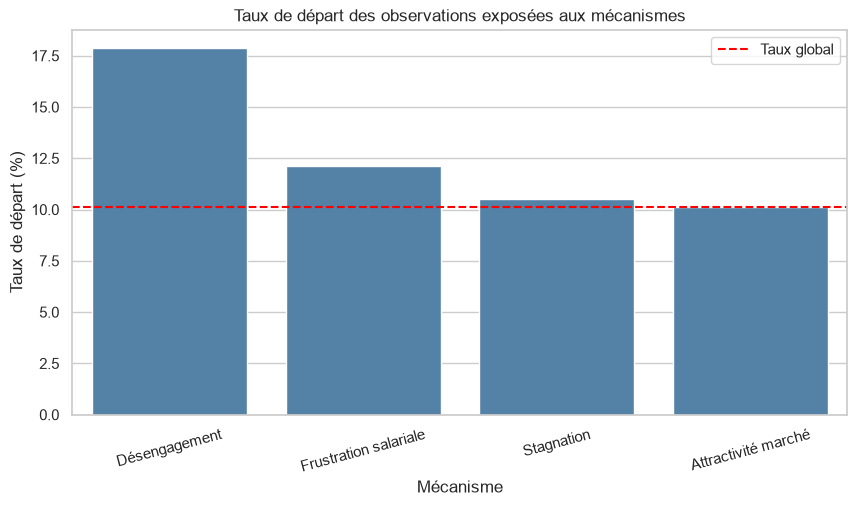

In [9]:
resume_mecanismes = []

mecanismes = {
    "Désengagement": "mecanisme_desengagement",
    "Frustration salariale": "mecanisme_frustration_salariale",
    "Stagnation": "mecanisme_stagnation",
    "Attractivité marché": "mecanisme_attractivite_marche"
}

for nom, colonne in mecanismes.items():
    exposition = train_prepare[colonne] >= 2
    resume_mecanismes.append({
        "mecanisme": nom,
        "effectif_expose": int(exposition.sum()),
        "taux_depart_exposes": train_prepare.loc[exposition, "target"].mean() * 100,
        "taux_depart_non_exposes": train_prepare.loc[~exposition, "target"].mean() * 100
    })

resume_mecanismes = pd.DataFrame(resume_mecanismes)
display(resume_mecanismes.round(2))

plt.figure(figsize=(10, 5))
sns.barplot(data=resume_mecanismes, x="mecanisme", y="taux_depart_exposes", color="steelblue")
plt.axhline(train_prepare["target"].mean() * 100, color="red", linestyle="--", label="Taux global")
plt.title("Taux de départ des observations exposées aux mécanismes")
plt.xlabel("Mécanisme")
plt.ylabel("Taux de départ (%)")
plt.xticks(rotation=15)
plt.legend()
plt.show()

# Partie B — Baseline et analyse des erreurs

## 10. Construction des variables pour la baseline

La validation correspond à juin 2024. Les périodes précédentes constituent l’apprentissage.

In [10]:
DATE_VALIDATION = pd.Timestamp("2024-06-30")
masque_train = train_prepare["date_reference"] < DATE_VALIDATION
masque_validation = train_prepare["date_reference"] == DATE_VALIDATION

colonnes_mecanismes = [
    "engagement_faible", "engagement_en_baisse", "absence_en_hausse",
    "mecanisme_desengagement", "bonne_performance", "salaire_sous_reference",
    "progression_salariale_faible", "mecanisme_frustration_salariale",
    "anciennete_importante", "promotion_lointaine", "mecanisme_stagnation",
    "poste_attractif", "experience_significative", "mecanisme_attractivite_marche"
]

colonnes_retrait = [
    "target", "id", "date_reference", "date_naissance", "date_embauche",
    "date_derniere_promotion", "date_derniere_absence"
]

X_comportement = train_prepare.drop(columns=colonnes_retrait)
X_baseline = X_comportement.drop(columns=colonnes_mecanismes)
y = train_prepare["target"]

X_train_base = X_baseline.loc[masque_train].copy()
X_val_base = X_baseline.loc[masque_validation].copy()
y_train = y.loc[masque_train]
y_val = y.loc[masque_validation]

print("Variables baseline :", X_train_base.shape[1])
print("Validation :", X_val_base.shape)

Variables baseline : 57
Validation : (1314, 57)


## 11. Fonction d’entraînement

La fonction entraîne CatBoost et recherche le meilleur seuil F1 sur la validation temporelle.

In [11]:
def entrainer_modele(X_train, X_val, nom):
    cat_cols = X_train.select_dtypes(include=["object", "string"]).columns.tolist()

    modele = CatBoostClassifier(
        iterations=1500,
        learning_rate=0.03,
        depth=6,
        l2_leaf_reg=7,
        loss_function="Logloss",
        eval_metric="AUC",
        auto_class_weights="Balanced",
        random_seed=42,
        verbose=False
    )

    modele.fit(
        X_train, y_train,
        cat_features=cat_cols,
        eval_set=(X_val, y_val),
        early_stopping_rounds=150
    )

    proba = modele.predict_proba(X_val)[:, 1]
    lignes = []
    for seuil in np.arange(0.20, 0.81, 0.01):
        pred = (proba >= seuil).astype(int)
        lignes.append({
            "seuil": round(float(seuil), 2),
            "f1": f1_score(y_val, pred),
            "precision": precision_score(y_val, pred, zero_division=0),
            "rappel": recall_score(y_val, pred, zero_division=0)
        })

    scores = pd.DataFrame(lignes)
    meilleur = scores.loc[scores["f1"].idxmax()]
    pred = (proba >= meilleur["seuil"]).astype(int)

    resume = {
        "modele": nom,
        "iteration": modele.get_best_iteration(),
        "auc": roc_auc_score(y_val, proba),
        "seuil": meilleur["seuil"],
        "f1": meilleur["f1"],
        "precision": meilleur["precision"],
        "rappel": meilleur["rappel"]
    }
    return modele, proba, pred, scores, resume

## 12. Entraînement de la baseline

In [12]:
modele_base, proba_base, pred_base, seuils_base, resume_base = entrainer_modele(
    X_train_base, X_val_base, "Baseline sans mécanismes"
)

display(pd.DataFrame([resume_base]))
print(classification_report(y_val, pred_base, digits=4))

,modele,iteration,auc,seuil,f1,precision,rappel
0,Baseline sans mécanismes,191,0.718804,0.57,0.304348,0.23431,0.434109


              precision    recall  f1-score   support

           0     0.9321    0.8456    0.8867      1185
           1     0.2343    0.4341    0.3043       129

    accuracy                         0.8052      1314
   macro avg     0.5832    0.6398    0.5955      1314
weighted avg     0.8636    0.8052    0.8296      1314



## 13. Classification des erreurs

Les quatre résultats possibles sont : vrai négatif, vrai positif, faux positif et faux négatif. Les faux négatifs sont particulièrement importants car ils correspondent aux départs que le modèle n’a pas détectés.

In [13]:
erreurs = train_prepare.loc[masque_validation].copy()
erreurs["probabilite_depart"] = proba_base
erreurs["prediction"] = pred_base

erreurs["type_resultat"] = np.select(
    [
        (erreurs["target"] == 0) & (erreurs["prediction"] == 0),
        (erreurs["target"] == 1) & (erreurs["prediction"] == 1),
        (erreurs["target"] == 0) & (erreurs["prediction"] == 1),
        (erreurs["target"] == 1) & (erreurs["prediction"] == 0)
    ],
    ["Vrai négatif", "Vrai positif", "Faux positif", "Faux négatif"],
    default="Inconnu"
)

display(erreurs["type_resultat"].value_counts().to_frame("effectif"))

,effectif
type_resultat,
Vrai négatif,1002
Faux positif,183
Faux négatif,73
Vrai positif,56


## 14. Profil moyen des erreurs

Cette synthèse aide à comprendre ce qui distingue les départs détectés des départs manqués.

In [14]:
variables_analyse = [
    "engagement_actuel", "engagement_moyen", "evolution_engagement",
    "ratio_salaire_reference", "taux_evolution_salaire",
    "performance_moyenne", "anciennete", "annees_depuis_promotion",
    "jours_abs_6m", "tendance_absence", "probabilite_depart"
]

profil_erreurs = erreurs.groupby("type_resultat")[variables_analyse].mean().round(3)
display(profil_erreurs)

,engagement_actuel,engagement_moyen,evolution_engagement,ratio_salaire_reference,taux_evolution_salaire,performance_moyenne,anciennete,annees_depuis_promotion,jours_abs_6m,tendance_absence,probabilite_depart
type_resultat,,,,,,,,,,,
Faux négatif,3.476,3.467,0.001,0.996,0.042,3.371,2.769,1.992,1.877,0.068,0.424
Faux positif,2.883,2.866,0.073,0.851,0.033,3.427,2.199,1.103,2.579,0.743,0.648
Vrai négatif,3.686,3.697,-0.019,1.046,0.060,3.464,2.478,1.252,1.410,0.165,0.356
Vrai positif,2.690,2.673,0.029,0.840,0.044,3.402,1.999,1.167,2.036,0.321,0.655


## 15. Mécanismes présents dans les erreurs

Cette cellule mesure la proportion de chaque type de résultat exposée aux quatre mécanismes.

In [15]:
for nom, colonne in mecanismes.items():
    erreurs[nom] = (erreurs[colonne] >= 2).astype(int)

analyse_erreurs_mecanismes = erreurs.groupby("type_resultat")[list(mecanismes.keys())].mean().mul(100).round(2)
display(analyse_erreurs_mecanismes)

,Désengagement,Frustration salariale,Stagnation,Attractivité marché
type_resultat,,,,
Faux négatif,10.96,43.84,41.10,30.14
Faux positif,15.85,85.79,43.17,30.05
Vrai négatif,4.69,46.31,42.61,30.84
Vrai positif,12.50,83.93,42.86,17.86


## 16. Faux négatifs prioritaires

Les faux négatifs à forte probabilité sont proches du seuil. Les faux négatifs à très faible probabilité correspondent à des formes de départ que le modèle comprend moins bien.

In [16]:
colonnes_affichage = [
    "id", "poste", "departement", "contrat", "grade",
    "engagement_actuel", "evolution_engagement",
    "ratio_salaire_reference", "performance_moyenne",
    "anciennete", "jours_abs_6m",
    "mecanisme_desengagement", "mecanisme_frustration_salariale",
    "mecanisme_stagnation", "mecanisme_attractivite_marche",
    "probabilite_depart"
]

faux_negatifs = erreurs.loc[erreurs["type_resultat"] == "Faux négatif"]

display(
    faux_negatifs.sort_values("probabilite_depart", ascending=True)[colonnes_affichage].head(25)
)

,id,poste,departement,contrat,grade,engagement_actuel,evolution_engagement,ratio_salaire_reference,performance_moyenne,anciennete,jours_abs_6m,mecanisme_desengagement,mecanisme_frustration_salariale,mecanisme_stagnation,mecanisme_attractivite_marche,probabilite_depart
4907,OBS004908,ANALYSTE RH,DEP06,CDD,G3,4.28,0.111566,1.062574,3.075,2.477755,0,0,1,1,1,0.196928
4210,OBS004211,ANALYSTE CX,DEP04,CDI,G3,4.40,-0.110188,1.007752,2.440,2.083504,0,0,1,1,2,0.208897
5406,OBS005407,SUPERVISEUR CENTRE DE CONTACTS,DEP04,CDI,G4,4.73,-0.227176,1.108719,4.030,4.082136,7,0,1,2,2,0.211951
4181,OBS004182,ANALYSTE CX,DEP04,CDD,G3,4.23,-0.313053,1.241787,3.250,2.477755,3,1,1,1,2,0.214944
5249,OBS005250,ANALYSTE VENTES,DEP02,CDI,G3,3.87,0.000023,1.020151,NaN,1.489391,5,0,1,1,0,0.216128
4241,OBS004242,TECHNICIEN RÉSEAU,DEP03,CDI,G1,3.51,NaN,1.201657,NaN,0.416153,6,1,1,1,0,0.217499
4225,OBS004226,CONSEILLER CLIENT,DEP04,CDD,G1,3.83,NaN,1.119403,4.560,0.583162,4,1,2,2,1,0.228016
4718,OBS004719,CHARGÉ GRANDS COMPTES,DEP02,CDD,G2,4.17,-0.479132,1.058824,3.415,1.500342,2,2,1,1,1,0.247092
4420,OBS004421,ANALYSTE VENTES,DEP02,CDD,G3,4.07,0.477088,1.097424,3.360,2.488706,0,0,1,1,1,0.262578
5141,OBS005142,TECHNICIEN RÉSEAU,DEP03,CDI,G2,3.67,0.173988,1.070175,2.615,1.084189,0,0,1,1,0,0.266423


## 17. Faux positifs les plus convaincants

Ces observations ressemblent fortement à des départs historiques mais sont restées dans l’entreprise pendant la fenêtre étudiée. Elles peuvent révéler des facteurs de rétention absents des données.

In [17]:
faux_positifs = erreurs.loc[erreurs["type_resultat"] == "Faux positif"]

display(
    faux_positifs.sort_values("probabilite_depart", ascending=False)[colonnes_affichage].head(25)
)

,id,poste,departement,contrat,grade,engagement_actuel,evolution_engagement,ratio_salaire_reference,performance_moyenne,anciennete,jours_abs_6m,mecanisme_desengagement,mecanisme_frustration_salariale,mecanisme_stagnation,mecanisme_attractivite_marche,probabilite_depart
4238,OBS004239,MANAGER RH,DEP06,CDI,G4,2.89,0.681432,0.830055,2.685,2.483231,11,2,1,1,1,0.786292
4964,OBS004965,CHARGÉ GRANDS COMPTES,DEP02,CDD,G4,3.10,-0.143471,0.000000,4.165,5.834360,0,0,3,3,3,0.772771
4425,OBS004426,CONSEILLER CLIENT,DEP04,CDD,G1,2.47,0.010107,0.826087,3.430,2.083504,5,1,2,1,1,0.769783
4957,OBS004958,INGÉNIEUR SYSTÈMES,DEP08,CDD,G3,2.57,-0.000161,0.901309,3.550,1.500342,7,2,3,2,1,0.768593
4254,OBS004255,CHARGÉ MARKETING,DEP07,CDI,G1,2.77,0.236754,0.822454,3.740,1.478439,1,1,3,2,1,0.764820
4844,OBS004845,CONSEILLER CLIENT,DEP04,CDI,G1,2.76,1.003992,0.764706,3.955,1.500342,6,2,3,2,1,0.764268
5272,OBS005273,MANAGER SERVICE CLIENT,DEP04,CDD,G5,2.95,-0.176032,0.846206,3.200,5.478439,7,1,2,1,1,0.753950
4177,OBS004178,MANAGER COMMERCIAL,DEP02,CDD,G5,2.94,-0.215070,0.850923,2.905,2.483231,3,1,1,1,1,0.753686
4626,OBS004627,INGÉNIEUR RÉSEAU,DEP03,CDI,G4,2.89,-0.120882,0.792079,3.335,3.917864,0,1,1,0,2,0.752936
5096,OBS005097,CONSEILLER CLIENT,DEP04,CDI,G2,2.70,NaN,0.870406,3.910,0.583162,7,2,3,2,1,0.746457


# Partie C — Test de l’apport des mécanismes

## 18. Entraînement avec les variables comportementales

Les mécanismes sont maintenant ajoutés au même modèle pour vérifier leur apport réel.

In [18]:
X_train_comportement = X_comportement.loc[masque_train].copy()
X_val_comportement = X_comportement.loc[masque_validation].copy()

modele_comportement, proba_comportement, pred_comportement, seuils_comportement, resume_comportement = entrainer_modele(
    X_train_comportement,
    X_val_comportement,
    "CatBoost avec mécanismes comportementaux"
)

comparaison = pd.DataFrame([resume_base, resume_comportement])
display(comparaison)

print("Gain F1 :", round(resume_comportement["f1"] - resume_base["f1"], 4))
print("Gain AUC :", round(resume_comportement["auc"] - resume_base["auc"], 4))

,modele,iteration,auc,seuil,f1,precision,rappel
0,Baseline sans mécanismes,191,0.718804,0.57,0.304348,0.234310,0.434109
1,CatBoost avec mécanismes comportementaux,181,0.721022,0.61,0.310231,0.270115,0.364341


Gain F1 : 0.0059
Gain AUC : 0.0022


## 19. Importance des mécanismes

Cette cellule vérifie si le modèle utilise réellement les variables comportementales créées.

In [19]:
importance = pd.DataFrame({
    "variable": X_train_comportement.columns,
    "importance": modele_comportement.get_feature_importance()
}).sort_values("importance", ascending=False)

display(importance.head(30))
display(importance.loc[importance["variable"].isin(colonnes_mecanismes)])

,variable,importance
12,engagement_actuel,10.517349
43,engagement_moyen,9.345143
40,ecart_salaire_reference,6.970064
39,ratio_salaire_reference,6.753255
36,anciennete,4.271728
35,age,3.766710
6,grade,3.285774
46,evolution_performance,3.077626
60,mecanisme_desengagement,2.919154
4,niveau_etude,2.364344


,variable,importance
60,mecanisme_desengagement,2.919154
57,engagement_faible,1.630359
62,salaire_sous_reference,1.413327
67,mecanisme_stagnation,1.065169
70,mecanisme_attractivite_marche,0.914419
64,mecanisme_frustration_salariale,0.895296
65,anciennete_importante,0.499010
63,progression_salariale_faible,0.329774
69,experience_significative,0.259245
68,poste_attractif,0.123952


## 20. Comparaison des erreurs avant et après

Nous mesurons combien de faux négatifs de la baseline sont récupérés par le modèle comportemental, et combien de nouvelles erreurs apparaissent.

In [20]:
comparaison_erreurs = pd.DataFrame({
    "y_reel": y_val.values,
    "prediction_base": pred_base,
    "prediction_comportement": pred_comportement,
    "proba_base": proba_base,
    "proba_comportement": proba_comportement
}, index=y_val.index)

faux_negatifs_recuperes = (
    (comparaison_erreurs["y_reel"] == 1) &
    (comparaison_erreurs["prediction_base"] == 0) &
    (comparaison_erreurs["prediction_comportement"] == 1)
).sum()

nouveaux_faux_positifs = (
    (comparaison_erreurs["y_reel"] == 0) &
    (comparaison_erreurs["prediction_base"] == 0) &
    (comparaison_erreurs["prediction_comportement"] == 1)
).sum()

print("Faux négatifs récupérés :", faux_negatifs_recuperes)
print("Nouveaux faux positifs :", nouveaux_faux_positifs)

Faux négatifs récupérés : 2
Nouveaux faux positifs : 12


## 21. Export des résultats

Les tableaux d’hypothèses, de comparaison et d’erreurs sont exportés pour le rapport et les prochaines analyses.

In [21]:
resume_mecanismes.to_csv("../reports/resume_mecanismes_comportementaux.csv", index=False)
comparaison.to_csv("../reports/comparaison_modeles_comportementaux.csv", index=False)
profil_erreurs.to_csv("../reports/profil_moyen_erreurs.csv")

colonnes_export = [
    "id", "target", "prediction", "probabilite_depart", "type_resultat",
    "mecanisme_desengagement", "mecanisme_frustration_salariale",
    "mecanisme_stagnation", "mecanisme_attractivite_marche"
]
erreurs[colonnes_export].to_csv("../reports/analyse_erreurs_validation_2024.csv", index=False)

print("Exports terminés dans reports.")

Exports terminés dans reports.


## Conclusion

Ce notebook ne cherche pas seulement à augmenter le score. Il évalue des hypothèses sur les mécanismes possibles des départs et examine les cas que le modèle comprend mal.

Trois résultats sont possibles :

- les mécanismes améliorent le F1 et sont conservés ;
- ils n’améliorent pas le F1 mais enrichissent l’explication métier ;
- ils révèlent de nouveaux sous-types de départs qui nécessitent une représentation différente.

La prochaine décision doit donc reposer à la fois sur le gain quantitatif et sur la qualité des explications fournies par l’analyse des erreurs.